In [1]:
%run ./notebook_setup.py

Project Root: /mnt/d/Projects/ISRO_Exoplanet
Source Dir: /mnt/d/Projects/ISRO_Exoplanet/src


/home/darxsouls/miniconda3/lib/python3.12/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


Project structure verified.


In [2]:
from preprocessing.bootstrap import build_registry
from preprocessing.identifiers import SelectorID

registry = build_registry()

print(registry.selectors.get(SelectorID.SIMPLE))
print(registry.selectors.get(SelectorID.SMART))

In [3]:
print(registry.selectors.keys())

print(tuple(registry.selectors.keys()))

print(registry.selectors.ids())

dict_keys([<SelectorID.SIMPLE: 'SIMPLE'>, <SelectorID.SMART: 'SMART'>])
(<SelectorID.SIMPLE: 'SIMPLE'>, <SelectorID.SMART: 'SMART'>)
(<SelectorID.SIMPLE: 'SIMPLE'>, <SelectorID.SMART: 'SMART'>)


In [2]:
from preprocessing.preprocess_lightcurve import (
    _load_dataframe, _validate_dataframe, _select_flux, _filter_quality, _remove_missing,
    _normalize_flux, _detrend, _build_metadata, _save_metadata, _save_parquet,

    preprocess_target
)

import matplotlib.pyplot as plt

from preprocessing.batch_preprocessor import (
    _load_master_catalog, _filter_targets, _update_preprocess_status,
    _save_master_catalog)

from config import *

from preprocessing.preprocessing_models import (
    PreprocessInput,
)

In [33]:
from dataclasses import fields

for field in fields(PreprocessInput):
    print(field.name, field.type)

tic_id <class 'int'>
label <class 'str'>
catalog <class 'str'>
parquet_file <class 'pathlib.Path'>


In [32]:
preprocess_input = PreprocessInput(

    tic_id=307210830,

    parquet_file=(
        PLANET_PARQUET_DIR
        / "TIC_1003831"
        / "lightcurve.parquet"
    ),

    metadata_file=(
        PLANET_METADATA_DIR
        / "TIC_1003831"
        / "metadata.json"
    ),

    label="PLANET",

    catalog="MASTER"

)

result = preprocess_target(
    preprocess_input,
    overwrite=True
)

print(result.steps_completed)
print(result.parquet_file)
print(result.metadata_file)

TypeError: PreprocessInput.__init__() got an unexpected keyword argument 'metadata_file'

In [6]:
preprocess_input = PreprocessInput(

    tic_id=1003831,

    parquet_file=(
        PLANET_PARQUET_DIR
        / "TIC_1003831"
        / "lightcurve.parquet"
    ),

    metadata_file=(
        PLANET_METADATA_DIR
        / "TIC_1003831"
        / "metadata.json"
    ),

    label="PLANET",

    catalog="MASTER"

)


TypeError: PreprocessInput.__init__() got an unexpected keyword argument 'metadata_file'

In [7]:
result = _load_dataframe(preprocess_input)

result = _validate_dataframe(result)

result = _select_flux(result)

result = _filter_quality(result)

result = _remove_missing(result)

result = _normalize_flux(result)

result = _detrend(result)

result = _build_metadata(result)

result = _save_parquet(result, overwrite=True)

result = _save_metadata(result, overwrite=True)

NameError: name 'preprocess_input' is not defined

In [8]:
master = _load_master_catalog(
    MASTER_CATALOG
)

targets = _filter_targets(
    master,
    max_targets=5
)

print(targets.shape)

print(targets.head())


 Loading Master Catalog 
Filtering Targets...
Targets Selected : 5

(5, 65)
    TICID SOURCE CATALOG_LABEL PRIMARY_LABEL       FINAL_CLASS LABEL_STATUS  \
0  737546     EB            EB            EB  Eclipsing Binary        Clean   
1  808243    TOI            PC            PC         Candidate        Clean   
2  857186    TOI            PC            PC         Candidate        Clean   
3  909930    TOI           APC           APC         Candidate        Clean   
4  927579     EB            EB            EB  Eclipsing Binary        Clean   

   IS_CONFLICT  N_SOURCES CATALOG_VERSION CATALOG_PROCESSED_DATE  ...  \
0        False          1         2025-06             2026-07-05  ...   
1        False          1         2025-06             2026-07-05  ...   
2        False          1         2025-06             2026-07-05  ...   
3        False          1         2025-06             2026-07-05  ...   
4        False          1         2025-06             2026-07-05  ...   

   prim_p

In [9]:
master = _update_preprocess_status(

    master_catalog=master,

    tic_id=2876,

    status=True

)

print(

    master.loc[
        master["TICID"] == 2876,
        "PREPROCESSED"
    ]

)

0    True
Name: PREPROCESSED, dtype: bool


In [10]:
_save_master_catalog(
    master_catalog=master,
    master_catalog_file=MASTER_CATALOG
)

In [11]:
master = pd.read_csv(MASTER_CATALOG)

print(
    master.loc[
        master["TICID"] == 2876,
        "PREPROCESSED"
    ]
)

0    True
Name: PREPROCESSED, dtype: bool


In [12]:
master = pd.read_csv(MASTER_CATALOG)

print(master.columns.tolist())

['TICID', 'SOURCE', 'CATALOG_LABEL', 'PRIMARY_LABEL', 'FINAL_CLASS', 'LABEL_STATUS', 'IS_CONFLICT', 'N_SOURCES', 'CATALOG_VERSION', 'CATALOG_PROCESSED_DATE', 'TOI', 'tfopwg_disp', 'PERIOD', 'TRANSIT_DURATION', 'TRANSIT_DEPTH', 'TMAG', 'RA', 'DEC', 'rowid', 'toipfx', 'ctoi_alias', 'pl_pnum', 'rastr', 'decstr', 'st_pmra', 'st_pmdec', 'pl_tranmid', 'pl_rade', 'pl_insol', 'pl_eqt', 'st_dist', 'st_teff', 'st_logg', 'st_rad', 'toi_created', 'rowupdate', 'EPOCH', 'MORPH_COEFF', 'PRIMARY_DEPTH', 'SECONDARY_DEPTH', 'SECTORS', 'signal_id', 'date_added', 'date_modified', 'source', 'pmra', 'pmdec', 'bjd0_uncert', 'period_uncert', 'prim_width_pf', 'prim_pos_pf', 'sec_width_pf', 'sec_pos_pf', 'prim_width_2g', 'prim_depth_2g', 'prim_pos_2g', 'sec_width_2g', 'sec_depth_2g', 'sec_pos_2g', 'DOWNLOADED', 'PREPROCESSED', 'BLS_COMPLETED', 'FEATURES_EXTRACTED', 'CLASSIFIED', 'FITTED']


In [13]:
from preprocessing.preprocess_lightcurve import (
    PreprocessInput,
    preprocess_target
)

from pathlib import Path

preprocess_input = PreprocessInput(

    tic_id=307210830,

    label="Planet",

    catalog="MASTER",

    parquet_file=(
        PLANET_PARQUET_DIR
        / "TIC_1003831"
        / "lightcurve.parquet"
    ),

    metadata_file=(
        PLANET_METADATA_DIR
        / "TIC_1003831"
        / "metadata.json"
    ),

)

result = preprocess_target(
    preprocess_input,
    overwrite=True
)

TypeError: PreprocessInput.__init__() got an unexpected keyword argument 'metadata_file'

In [14]:
print(result.parquet_file)
print(result.metadata_file)

print(result.parquet_file.exists())
print(result.metadata_file.exists())

NameError: name 'result' is not defined

In [15]:
import pandas as pd

df = pd.read_parquet(
    result.parquet_file
)

df.head()

NameError: name 'result' is not defined

In [ ]:
print(df.shape)

print(df.columns.tolist())

(73612, 10)
['TICID', 'SECTOR', 'TIME', 'FLUX', 'FLUX_ERR', 'QUALITY', 'MOM_CENTR1', 'MOM_CENTR2', 'DETRENDED_FLUX', 'TREND']


In [ ]:
import json

with open(result.metadata_file) as f:

    metadata = json.load(f)

print(metadata.keys())

dict_keys(['target', 'dataset', 'quality', 'missing_values', 'normalization', 'detrending', 'pipeline', 'validation'])


In [ ]:
print(result.steps_completed)

['load_dataframe', 'validate_dataframe', 'select_flux', 'filter_quality', 'remove_missing', 'normalize_flux', 'detrend', 'build_metadata', 'save_parquet', 'save_metadata']


In [ ]:
print(df.describe())

           TICID        SECTOR          TIME          FLUX      FLUX_ERR  \
count    73612.0  73612.000000  73612.000000  73612.000000  73612.000000   
mean   1003831.0     57.567937   2887.741699      0.995651      0.001429   
std          0.0     32.156880    884.410349      0.019195      0.000053   
min    1003831.0      8.000000   1518.028224      0.856806      0.001269   
25%    1003831.0     34.000000   2236.727418      0.980091      0.001391   
50%    1003831.0     61.000000   2973.949064      1.000000      0.001448   
75%    1003831.0     88.000000   3706.997915      1.008970      0.001468   
max    1003831.0     99.000000   4071.018190      1.029755      0.001601   

       QUALITY    MOM_CENTR1    MOM_CENTR2  DETRENDED_FLUX         TREND  
count  73612.0  73612.000000  73612.000000    73612.000000  73612.000000  
mean       0.0    937.595591    645.127624        0.999921      0.995724  
std        0.0    249.591203    433.163307        0.002054      0.018833  
min        0.0 

In [ ]:
print(df.isna().sum())

TICID             0
SECTOR            0
TIME              0
FLUX              0
FLUX_ERR          0
QUALITY           0
MOM_CENTR1        0
MOM_CENTR2        0
DETRENDED_FLUX    0
TREND             0
dtype: int64


In [ ]:
import numpy as np

print(

    np.isinf(
        df.select_dtypes("number")
    ).sum()

)

TICID             0
SECTOR            0
TIME              0
FLUX              0
FLUX_ERR          0
QUALITY           0
MOM_CENTR1        0
MOM_CENTR2        0
DETRENDED_FLUX    0
TREND             0
dtype: int64


In [ ]:
print(

    df.duplicated().sum()

)

0


In [ ]:
print(

    df["TIME"].is_monotonic_increasing

)

print(

    df["FLUX"].median()

)

print(

    df["DETRENDED_FLUX"].median()

)

print(

    df["FLUX_ERR"].min()

)

print(

    df["FLUX_ERR"].max()

)

print(

    df["TREND"].describe()

)


True
1.0
0.9999994930541187
0.0012694147
0.0016008059
count    73612.000000
mean         0.995724
std          0.018833
min          0.893301
25%          0.980152
50%          1.000031
75%          1.008733
max          1.025931
Name: TREND, dtype: float64


In [ ]:
print(

    df.groupby("SECTOR").size()

)

SECTOR
8     12907
34    16854
61    15412
88    17654
99    10785
dtype: int64


In [ ]:
print(metadata["validation"])

print(metadata["quality"])

print(metadata["missing_values"])

print(metadata["normalization"])

print(metadata["detrending"])

{'tic_id': 1003831, 'rows': 81729, 'columns': 12, 'n_sectors': 5, 'validated': True}
{'quality_flag': 0, 'original_rows': 81729, 'removed_rows': 8117, 'remaining_rows': 73612, 'retained_fraction': 0.9007, 'retained_percentage': 90.07}
{'original_rows': 73612, 'missing_rows_removed': 0, 'duplicates_removed': 0, 'total_removed': 0, 'remaining_rows': 73612, 'retained_fraction': 1.0, 'retained_percentage': 100.0}
{'method': 'median', 'normalization_factor': 7818.9091796875, 'median_flux_after': 1.0, 'flux_err_scaled': True}
{'method': 'wotan', 'filter': 'biweight', 'window_length_days': 0.75, 'break_tolerance': 0.5, 'edge_cutoff': 0.0, 'rows': 73612, 'n_sectors': 5}


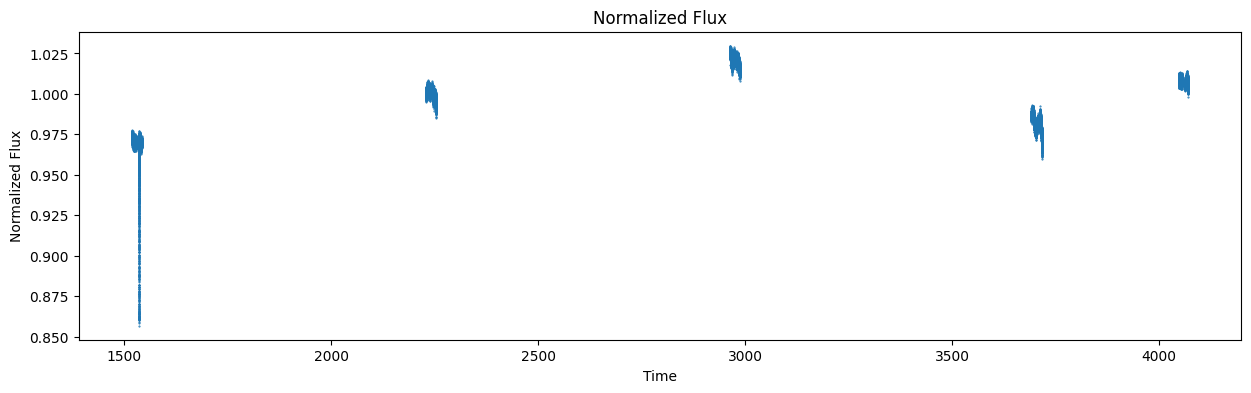

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15,4))

plt.plot(
    df["TIME"],
    df["FLUX"],
    ".",
    markersize=1
)

plt.xlabel("Time")

plt.ylabel("Normalized Flux")

plt.title("Normalized Flux")


plt.show()

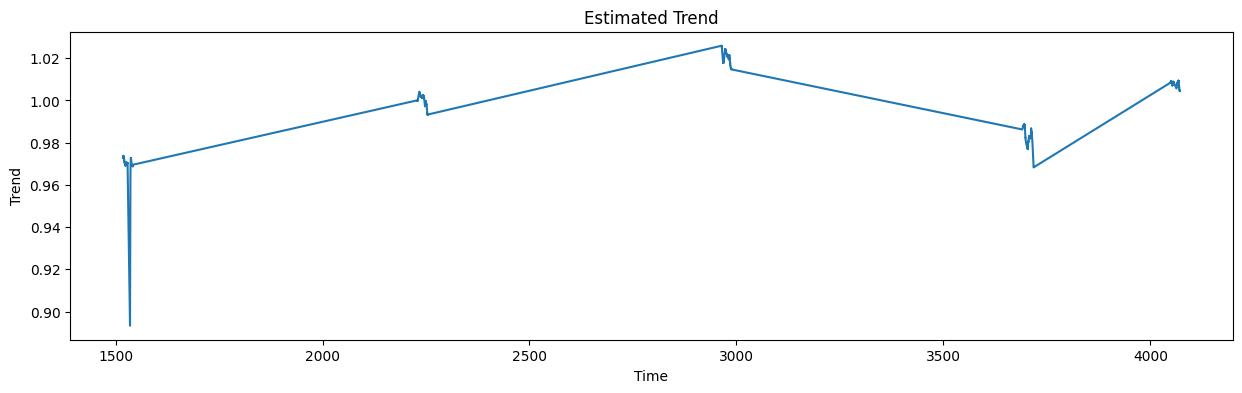

In [ ]:
plt.figure(figsize=(15,4))

plt.plot(
    df["TIME"],
    df["TREND"]
)

plt.xlabel("Time")

plt.ylabel("Trend")

plt.title("Estimated Trend")

plt.show()

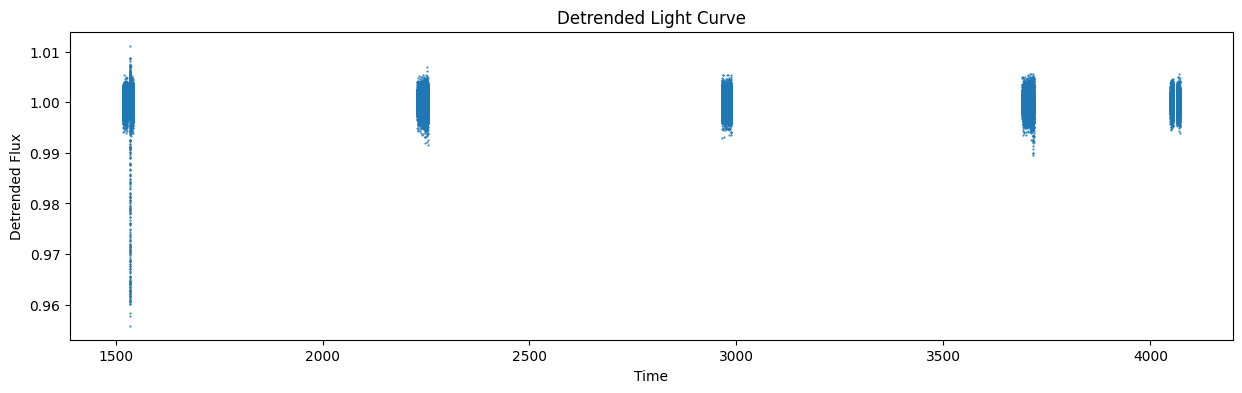

In [ ]:
plt.figure(figsize=(15,4))

plt.plot(

    df["TIME"],

    df["DETRENDED_FLUX"],

    ".",

    markersize=1

)

plt.xlabel("Time")

plt.ylabel("Detrended Flux")

plt.title("Detrended Light Curve")

plt.show()

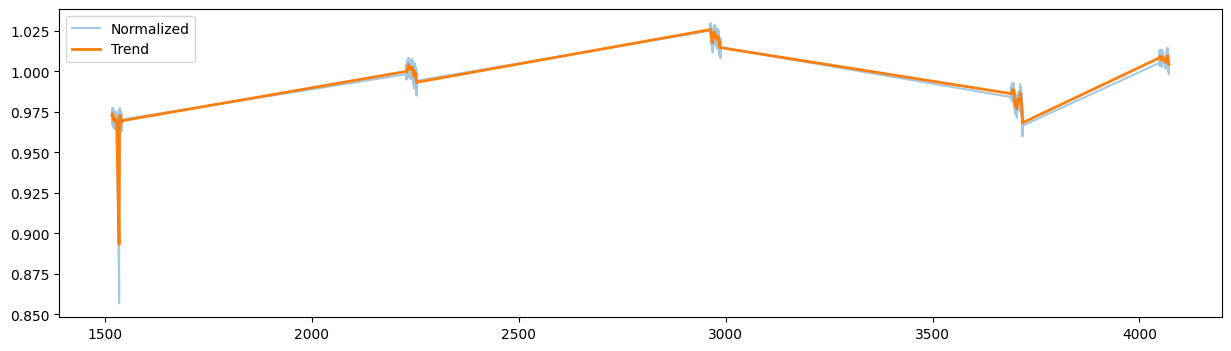

In [ ]:
plt.figure(figsize=(15,4))

plt.plot(

    df["TIME"],

    df["FLUX"],

    alpha=0.4,

    label="Normalized"

)

plt.plot(

    df["TIME"],

    df["TREND"],

    linewidth=2,

    label="Trend"

)

plt.legend()

plt.show()

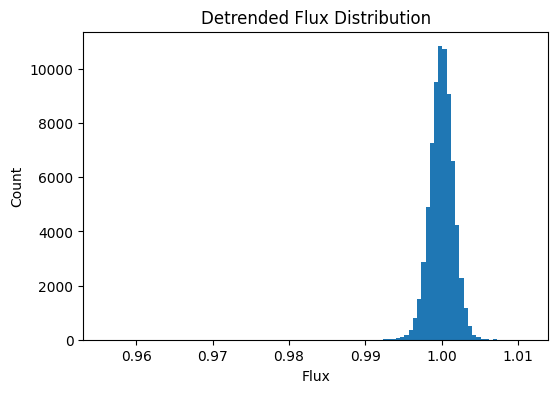

In [ ]:
plt.figure(figsize=(6,4))

plt.hist(

    df["DETRENDED_FLUX"],

    bins=100

)

plt.xlabel("Flux")

plt.ylabel("Count")

plt.title("Detrended Flux Distribution")

plt.show()

BATCH PROCESSOR

In [16]:
from preprocessing.batch_preprocessor import preprocess_dataset

master, log = preprocess_dataset(

    master_catalog_file=MASTER_CATALOG,

    # processed_directory=PROCESSED_DIR,

    log_file=PREPROCESS_LOG_FILE,

    overwrite=True,

    max_targets=5

)


 Loading Master Catalog 
Filtering Targets...
Targets Selected : 5

Preprocessing Targets...


Preprocessing: 100%|██████████| 5/5 [00:00<00:00, 6243.38it/s]


Failed TIC 2876
Reason : PipelineConfig.__init__() missing 1 required positional argument: 'pipeline_name'

Failed TIC 4711
Reason : PipelineConfig.__init__() missing 1 required positional argument: 'pipeline_name'

Failed TIC 17361
Reason : PipelineConfig.__init__() missing 1 required positional argument: 'pipeline_name'

Failed TIC 47667
Reason : PipelineConfig.__init__() missing 1 required positional argument: 'pipeline_name'

Failed TIC 56884
Reason : PipelineConfig.__init__() missing 1 required positional argument: 'pipeline_name'


Saving Preprocessing Log...

 Preprocessing Complete 
Processed : 0

   Planet            : 0
   Candidate         : 0
   False Positive    : 0
   Eclipsing Binary  : 0

Skipped           : 0
Failed            : 5

Success Rate      : 0.00%

Average Time/TIC  : 0.00 sec



In [17]:
log

,tic_id,label,status,elapsed_seconds,parquet_file,metadata_file,message
0,2876,Candidate,FAILED,0.000122,None,None,PipelineConfig.__init__() missing 1 required p...
1,4711,Candidate,FAILED,0.000022,None,None,PipelineConfig.__init__() missing 1 required p...
2,17361,Candidate,FAILED,0.000014,None,None,PipelineConfig.__init__() missing 1 required p...
3,47667,Candidate,FAILED,0.000011,None,None,PipelineConfig.__init__() missing 1 required p...
4,56884,Candidate,FAILED,0.000010,None,None,PipelineConfig.__init__() missing 1 required p...


In [18]:
print(

    log["status"].value_counts()

)

print()

print(

    log["elapsed_seconds"].describe()

)

status
FAILED    5
Name: count, dtype: int64

count    5.000000
mean     0.000036
std      0.000048
min      0.000010
25%      0.000011
50%      0.000014
75%      0.000022
max      0.000122
Name: elapsed_seconds, dtype: float64


In [19]:
slowest = log.loc[
    log["elapsed_seconds"].idxmax()
]

print(slowest)

tic_id                                                          2876
label                                                      Candidate
status                                                        FAILED
elapsed_seconds                                             0.000122
parquet_file                                                    None
metadata_file                                                   None
message            PipelineConfig.__init__() missing 1 required p...
Name: 0, dtype: object


In [20]:
master, log = preprocess_dataset(

    master_catalog_file=MASTER_CATALOG,

    # processed_directory=PROCESSED_DIR,

    log_file=PREPROCESS_LOG_FILE,

    overwrite=True,

    max_targets=5

)


 Loading Master Catalog 
Filtering Targets...
Targets Selected : 5

Preprocessing Targets...


Preprocessing: 100%|██████████| 5/5 [00:00<00:00, 8087.74it/s]


Failed TIC 2876
Reason : PipelineConfig.__init__() missing 1 required positional argument: 'pipeline_name'

Failed TIC 4711
Reason : PipelineConfig.__init__() missing 1 required positional argument: 'pipeline_name'

Failed TIC 17361
Reason : PipelineConfig.__init__() missing 1 required positional argument: 'pipeline_name'

Failed TIC 47667
Reason : PipelineConfig.__init__() missing 1 required positional argument: 'pipeline_name'

Failed TIC 56884
Reason : PipelineConfig.__init__() missing 1 required positional argument: 'pipeline_name'


Saving Preprocessing Log...

 Preprocessing Complete 
Processed : 0

   Planet            : 0
   Candidate         : 0
   False Positive    : 0
   Eclipsing Binary  : 0

Skipped           : 0
Failed            : 5

Success Rate      : 0.00%

Average Time/TIC  : 0.00 sec



In [21]:
master_catalog = pd.read_csv(MASTER_CATALOG)
print(

    master_catalog[
        ["TICID", "PREPROCESSED"]
    ].head(10)

)

    TICID  PREPROCESSED
0    2876          True
1    4711          True
2   17361          True
3   23111         False
4   47667          True
5   56884          True
6   91961          True
7  101462          True
8  120016          True
9  160023          True


In [22]:
master = pd.read_csv(
    MASTER_CATALOG
)

targets = master[
    (master["DOWNLOADED"] == True)
    &
    (master["PREPROCESSED"] == False)
]

print(
    targets[["TICID", "PREPROCESSED"]].head(10)
)

      TICID  PREPROCESSED
11   737546         False
12   808243         False
13   857186         False
14   909930         False
15   927579         False
16  1003831         False
17  1018843         False
18  1042432         False
19  1045298         False
20  1103432         False


Smart selector V1

In [3]:
from preprocessing.preprocessing_models import (
    PreprocessInput,
)

preprocess_input = PreprocessInput(

    tic_id=307210830,

    label="Planet",

    catalog="MASTER",

    parquet_file=(
        PLANET_PARQUET_DIR
        / "TIC_1003831"
        / "lightcurve.parquet"
    ),

)

In [4]:
# ==========================================================
# SmartSelector Integration Test
# ==========================================================

import pandas as pd

from preprocessing.bootstrap import build_registry
from preprocessing.identifiers import SelectorID

from preprocessing.config import (
    FrameworkConfig,
    PipelineConfig,
    PreprocessingConfig,
)


# ----------------------------------------------------------
# Build Registry
# ----------------------------------------------------------

registry = build_registry()

selector = registry.selectors.get(
    SelectorID.SMART
)

# ----------------------------------------------------------
# Load Raw Data
# ----------------------------------------------------------

raw_dataframe = pd.read_parquet(
    preprocess_input.parquet_file
)

print("=" * 60)
print("Raw Data")
print("=" * 60)

print(raw_dataframe.shape)

print()

print(raw_dataframe.columns.tolist())

# ----------------------------------------------------------
# Build Configuration
# ----------------------------------------------------------

config = PreprocessingConfig(

    framework=FrameworkConfig(),

    pipeline=PipelineConfig(
        pipeline_name="Smart Selector Test",

        selector=SelectorID.SMART,
    ),

)

# ----------------------------------------------------------
# Run Smart Selector
# ----------------------------------------------------------

result = selector.select(

    raw_dataframe=raw_dataframe,

    input_data=preprocess_input,

    config=config,

)

# ----------------------------------------------------------
# Display Result
# ----------------------------------------------------------

print("\n" + "=" * 60)
print("Selection Result")
print("=" * 60)

print("Flux Type:")
print(result.selected_flux_type)

print()

print("Selection Method:")
print(result.selection_method)

print()

print("Flux Column:")
print(result.selected_flux.flux_column)

print()

print("Flux Error Column:")
print(result.selected_flux.flux_error_column)

print()

print("Scores:")
print(result.selection_scores)

print()

print("Metadata:")
print(result.metadata)

print()

print("Flux Preview:")
print(result.selected_flux.flux.head())

Raw Data
(81729, 12)

['TICID', 'SECTOR', 'TIME', 'SAP_FLUX', 'SAP_FLUX_ERR', 'PDCSAP_FLUX', 'PDCSAP_FLUX_ERR', 'QUALITY', 'PSF_CENTR1', 'PSF_CENTR2', 'MOM_CENTR1', 'MOM_CENTR2']
Ranked Candidates
SAP
1.0
{'completeness': 1.0}

PDCSAP
0.9006839677470665
{'completeness': 0.9006839677470665}


Selection Result
Flux Type:
SAP

Selection Method:
SMART

Flux Column:
SAP_FLUX

Flux Error Column:
SAP_FLUX_ERR

Scores:
{'SAP': {'score': 1.0, 'completeness': 1.0}}

Metadata:
{'selected_flux': 'SAP', 'selected_score': 1.0}

Flux Preview:
0    7620.375488
1    7584.507324
2    7573.278320
3    7602.992676
4    7579.889160
Name: SAP_FLUX, dtype: float32


In [6]:
print(result.representations.keys())

AttributeError: 'FluxSelectionResult' object has no attribute 'representations'

In [37]:
raw_dataframe = pd.read_parquet(
    preprocess_input.parquet_file
)

print(raw_dataframe.shape)
print(raw_dataframe.columns.tolist())

(81729, 12)
['TICID', 'SECTOR', 'TIME', 'SAP_FLUX', 'SAP_FLUX_ERR', 'PDCSAP_FLUX', 'PDCSAP_FLUX_ERR', 'QUALITY', 'PSF_CENTR1', 'PSF_CENTR2', 'MOM_CENTR1', 'MOM_CENTR2']
